# TOI-contam: JupyterLab example

This notebook demonstrates how to run the `toi-contam` package in a JupyterLab environment. It shows a programmatic invocation (via `run_analysis`). Replace `WORKDIR` with your project path if needed.

## 1) Create a new notebook / set working directory

Set the working directory to your project root (where `pyproject.toml` lives). Replace the `WORKDIR` value below with the correct path for your system.

In [1]:
from pathlib import Path
import os
# Replace this with your local project path if needed
WORKDIR = '/home/mantovan/CODE/toi-contam/example_folder'
os.chdir(WORKDIR)
print('Working directory set to', Path.cwd())

Working directory set to /home/mantovan/CODE/toi-contam/example_folder


## 2) Import required libraries

Import the main scientific libraries and the `toi-contam` programmatic entry point.

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

# Try to import the programmatic API (may fail if package not installed yet)
try:
    from toi_contam.analysis import run_analysis
    print('Imported run_analysis from toi_contam.analysis')
except Exception as exc:
    print('Could not import toi_contam (install package first).', exc)

Imported run_analysis from toi_contam.analysis


## 3) Load or select example target

Choose a target TOI name or a local folder containing TPF-like files. 
The example below uses `TOI154.01` (a known false positive, a nearby eclipsing binary, blended in the TESS photometry) as a demonstration target; change as needed.

In [3]:
# Example target (change to your TOI or local folder)
target = 'TOI154.01'
output_dir = 'TOI154_contam'
print('Target', target, '-> outputs will be written to', output_dir)

Target TOI154.01 -> outputs will be written to TOI154_contam


## 4) Run the code

Call `run_analysis()`. This runs the script and writes outputs into the chosen `output_dir`.

Starting programmatic analysis...
In preparation for Gaia DR4, the Gaia archive is in evolution. Unfortunately, it may be unstable at times and particular types of queries may time out. Please consider registering for a user account (https://www.cosmos.esa.int/web/gaia-users/register). For questions or advice, please contact the Gaia helpdesk (https://www.cosmos.esa.int/web/gaia/gaia-helpdesk).

TESS contamination analysis
Target: TOI154.01

[progress] Target metadata ready: TOI=True | source=qlp-s27-ffi
[progress] Querying nearby catalogs: search radius = 10 TESS pixels
[progress] Catalog query complete: Gaia matches = 123
[progress] Sector used: 27
|████████████████████████████████████████| 123/123 [100%] in 0.4s (342.56/s) 
[progress] Computing contamination summary: writing the contamination tables and final figures

Analysis complete
Output directory: TOI154_contam
Analysis finished — check TOI154_contam


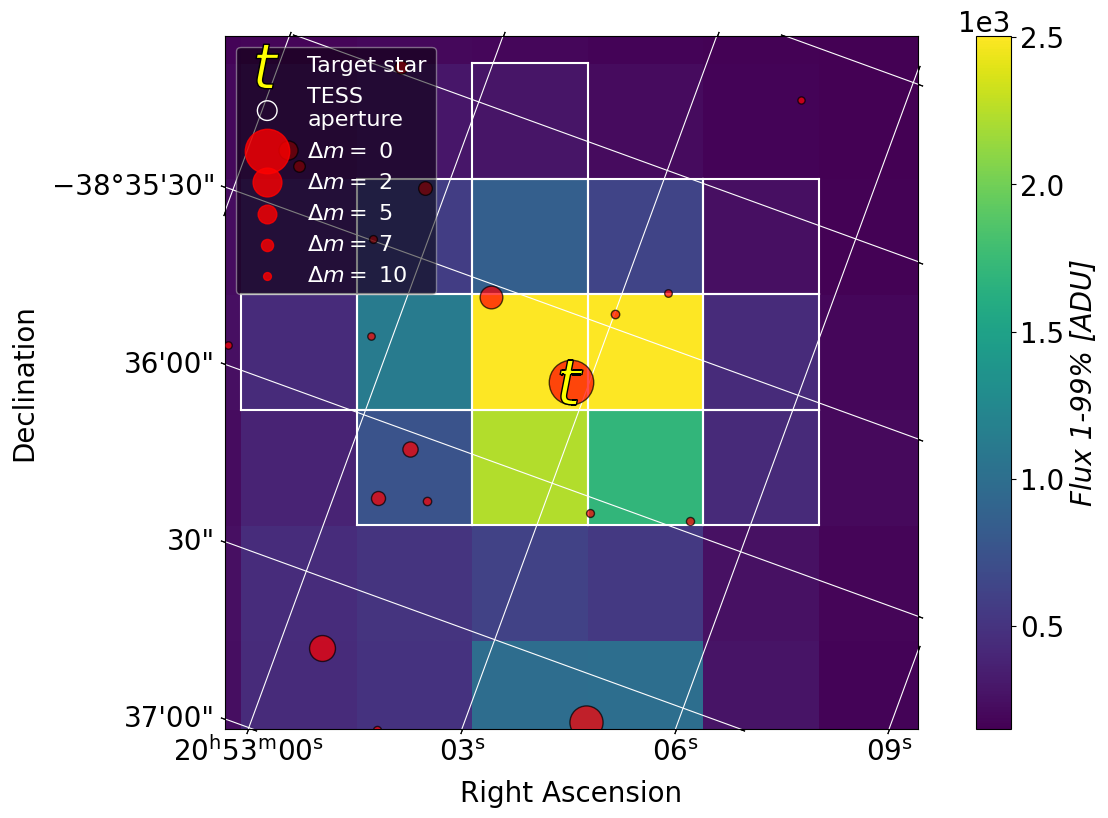

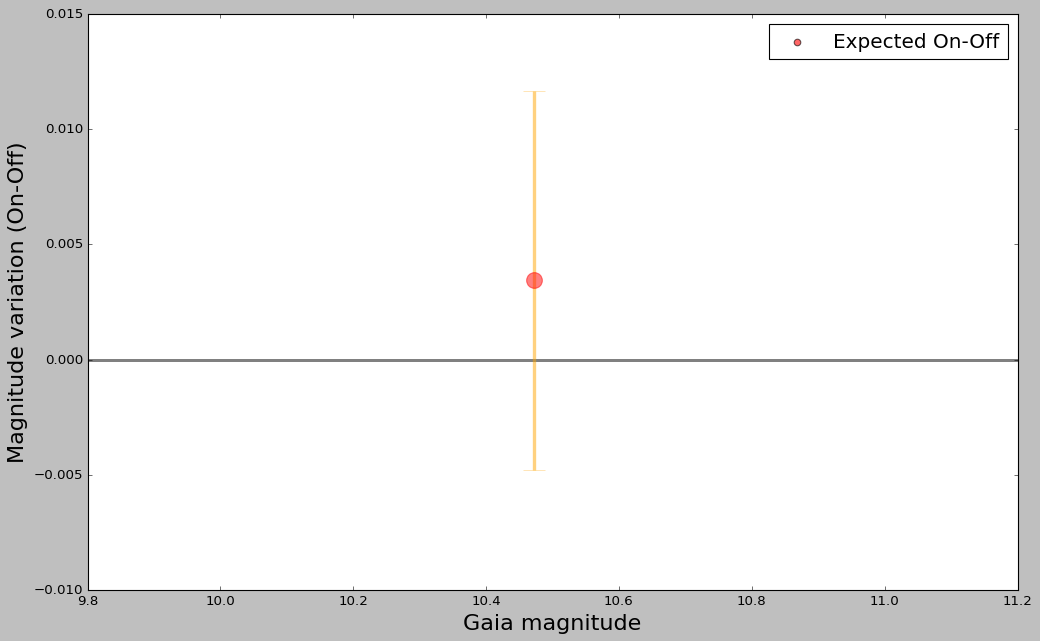

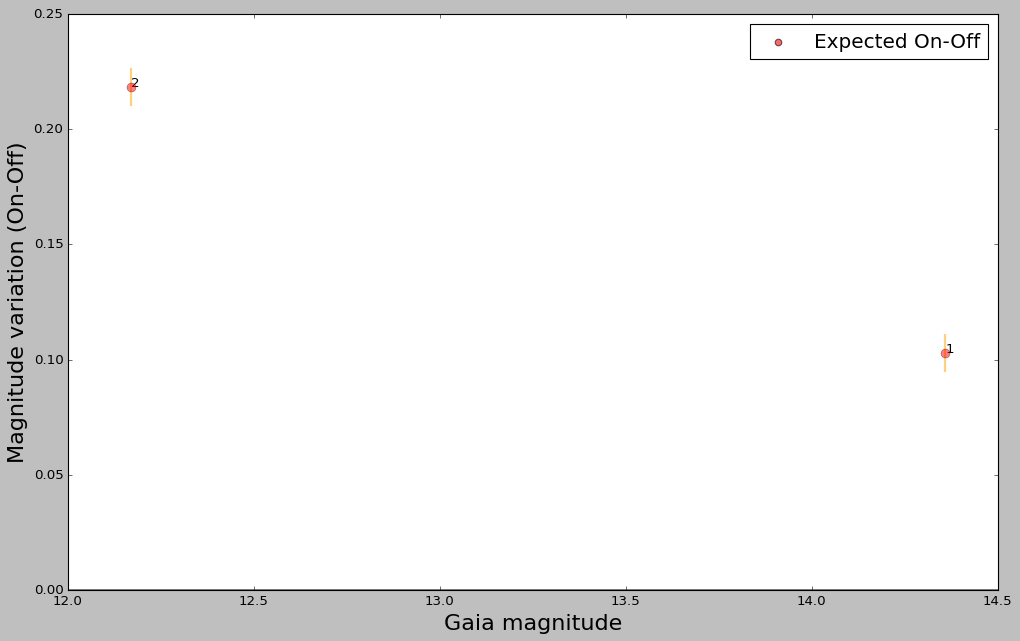

In [4]:
# Programmatic invocation example
from toi_contam.analysis import run_analysis

print('Starting programmatic analysis...')
run_analysis(target=target, custom_aperture=0, sector=None, dark=False, output_dir=output_dir)
print('Analysis finished — check', output_dir)

## 5) Compare the result of the contamination analysis (Useful_results.csv) with seeing-limited photometry. 

This is a specific case of a nearby eclipsing binary (NEB, TOI-154.01), as an example to show that the predicted depth estimated by toi-contam is compatible with real undiluted observations.

In [5]:
df = pd.read_csv('TIC389525208-01_20180915_El_Sauce_Rc_Measurements.txt', sep = '\s+')

In [6]:
df2 = pd.read_csv(output_dir+'/Useful_results.csv', sep = ',')

In [7]:
median_flux = df['rel_flux_T2'] / np.median(df['rel_flux_T2'][0:120])
median_flux_err = df['rel_flux_err_T2'] / np.median(df['rel_flux_T2'][0:120])

x = df['BJD_TDB'] - 2457000
y = median_flux

In [8]:
# binned lightcurve

time_array = np.arange(np.min(x), np.max(x), 300./86400.)
time_bins, _, _ = binned_statistic(x, x, bins=time_array, statistic='mean')
flux_bins, _, _ = binned_statistic(x, y , bins=time_array, statistic='mean')
eflux_bins, _, _ = binned_statistic(x, y, bins=time_array, statistic='std')
flux_counts, _, _ = binned_statistic(x, x, bins=time_array, statistic='count')
time_binned = time_bins[flux_counts>0.5]
flux_binned = flux_bins[flux_counts>0.5] 
eflux_binned = eflux_bins[flux_counts>0.5] /np.sqrt(flux_counts[flux_counts>0.5])

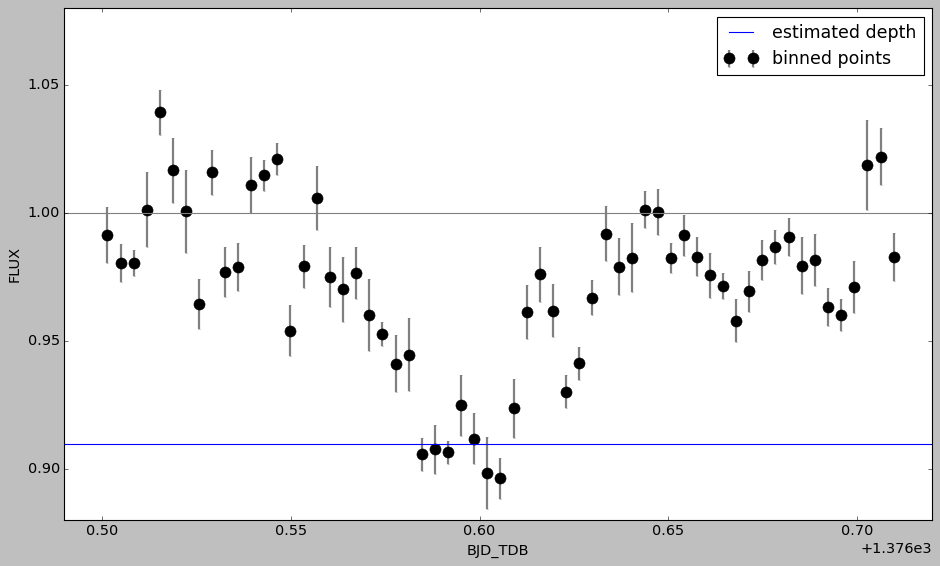

In [9]:
#figure 

plt.close()
plt.rcParams['font.size'] = 13
plt.figure(figsize=(14, 8))

plt.errorbar(time_binned, flux_binned,yerr=eflux_binned, 
             fmt='k.', markersize = 20, zorder = 1, linewidth = 2, 
             ecolor = 'gray', capsize = 1, label = 'binned points')

plt.xlabel('BJD_TDB')
plt.ylabel('FLUX')

plt.xlim(1376.49, 1376.72)
plt.ylim(0.88, 1.08)

plt.axhline(1, color = 'grey')
plt.axhline(1 - df2['depth_(flux)'][1], label = 'estimated depth')

plt.legend()

plt.show()